# Final screenshots and review of the dashboard

**Data sources:** the dashboard in `../dashboard/` and the results of `build_dashboard.ipynb` (`build_dashboard_output/`) and `browser_checks.ipynb` (`browser_checks_output/`).
**Date:** 2026-11-06, updated 2026-11-09 for the refined dashboard
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Task 6.8. Takes the screenshots of both screens for the Part 6 document (`../images/`) and reviews the four checklists of the course skills: DRACO, data-viz best practices, accessible notebooks and WCAG 2.2 AA + COGA. Each item gets a result and its evidence; items not met are listed for the students, who approve the review. Updated after the students refined the dashboard (16:9 screen without scrolling, Okabe–Ito colours and night mode, new chart types).

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: the four checklists](#4.-Analysis:-the-four-checklists)
5. [Accessible visualisation: screenshots](#5.-Accessible-visualisation:-screenshots)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import json
import re
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd
import nbformat
from playwright.async_api import async_playwright   # if missing: pip install playwright, then: playwright install chromium

CODE_DIR = Path('.')
DASHBOARD_DIR = Path('../dashboard').resolve()
IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('final_review_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
NOTEBOOKS = ['build_dashboard.ipynb', 'browser_checks.ipynb']

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| nbformat', nbformat.__version__,
      '| playwright', version('playwright'))

Python 3.13.18 | pandas 3.0.5 | nbformat 5.11.1 | playwright 1.63.0


## 1. Data loading

The results of the two notebooks that build and test the dashboard.

In [2]:
# ── Results of the other notebooks ───────────────────────────────────────────
draco = pd.read_csv('build_dashboard_output/draco_checks.csv')
values = pd.read_csv('build_dashboard_output/chart_value_checks.csv')
sizes = pd.read_csv('build_dashboard_output/chart_size_checks.csv')
export = pd.read_csv('build_dashboard_output/export_checks.csv')
first_load = pd.read_csv('browser_checks_output/first_load_checks.csv')
window_fit = pd.read_csv('browser_checks_output/window_fit_checks.csv')
selection = pd.read_csv('build_dashboard_output/selection_sort_checks.csv')
colours = pd.read_csv('build_dashboard_output/selected_colour_checks.csv')
interactions = pd.read_csv('browser_checks_output/interaction_checks.csv')
keyboard = pd.read_csv('browser_checks_output/keyboard_checks.csv')
alternatives = pd.read_csv('browser_checks_output/text_alternative_checks.csv')
operability = pd.read_csv('browser_checks_output/wcag_operability_review.csv')
wcag_other = pd.read_csv('browser_checks_output/wcag_other_items_review.csv')
text_audit = pd.read_csv('browser_checks_output/contrast_and_text_size.csv')
layout = pd.read_csv('browser_checks_output/zoom_and_tablet_checks.csv')
pd.DataFrame([(name, len(table)) for name, table in [('DRACO rule checks', draco), ('chart value renders', values),
              ('chart size checks', sizes), ('export checks', export), ('selection and sort checks', selection),
              ('colour checks', colours), ('first-load checks', first_load), ('window sizes', window_fit),
              ('interaction checks', interactions), ('keyboard checks', keyboard), ('text alternative checks', alternatives),
              ('WCAG operability items', operability), ('other WCAG items', wcag_other), ('texts measured', text_audit),
              ('zoom and tablet cases', layout)]], columns=['result file', 'rows'])

,result file,rows
0,DRACO rule checks,239
1,chart value renders,234
2,chart size checks,8
3,export checks,8
4,selection and sort checks,25
5,colour checks,10
6,first-load checks,4
7,window sizes,12
8,interaction checks,55
9,keyboard checks,44


## 2. Initial exploration

How many checks pass in each file, before the review.

In [3]:
# ── Pass rate of every check file ─────────────────────────────────────────────
pass_rates = pd.DataFrame([
    ('DRACO hard rules', draco['passes'].mean()),
    ('values drawn = pandas', values['same values'].mean()),
    ('selection and sort', selection['passes'].mean()),
    ('data colours 3:1 in both themes', colours['passes 3:1'].mean()),
    ('screens fit 1536 x 864 without scrolling', first_load['fits 1536 x 864 without scrolling'].mean()),
    ('specs.js and data.js = notebook', export['same as in the notebook'].mean()),
    ('interactions', interactions['passes'].mean()),
    ('keyboard', keyboard['passes'].mean()),
    ('text alternatives and tables', alternatives['passes'].mean()),
    ('text contrast (WCAG AA)', text_audit['passes'].mean()),
], columns=['checks', 'share passing']).round(3)
pass_rates

,checks,share passing
0,DRACO hard rules,1.0
1,values drawn = pandas,1.0
2,selection and sort,1.0
3,data colours 3:1 in both themes,1.0
4,screens fit 1536 x 864 without scrolling,1.0
5,specs.js and data.js = notebook,1.0
6,interactions,1.0
7,keyboard,1.0
8,text alternatives and tables,1.0
9,text contrast (WCAG AA),1.0


In [4]:
# ── Share of the content area taken by each chart box, measured in the browser at 1536 x 864 ─
# Content area: the KPI row and the charts (without header, filter panel and footer), as in Part 4
AREA_READ = """() => {
    const box = e => e.getBoundingClientRect();
    const kpis = box(document.querySelector('.kpis')), charts = box(document.getElementById('charts'));
    const area = kpis.width * (charts.bottom - kpis.top);
    return [...document.querySelectorAll('figure.chart')].map(f => [f.querySelector('h3').textContent, Math.round(1000 * box(f).width * box(f).height / area) / 10]);
}"""
area_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    page = await browser.new_page(viewport={'width': 1536, 'height': 864})
    for name in ['index.html', 'detail.html']:
        await page.goto((DASHBOARD_DIR / name).as_uri())
        await page.wait_for_selector('body[data-dashboard-ready="true"]')
        area_rows += [(name, title, share) for title, share in await page.evaluate(AREA_READ)]
    await browser.close()
chart_areas = pd.DataFrame(area_rows, columns=['page', 'chart box', '% of the content area'])
largest = chart_areas.groupby('page')['% of the content area'].max()
chart_areas

,page,chart box,% of the content area
0,index.html,In which months do the city and the resort rec...,45.8
1,index.html,In which months are most bookings cancelled?,18.8
2,index.html,How does the price per night change through th...,18.8
3,detail.html,Which countries do the guests come from?,22.2
4,detail.html,"When does each market travel, and how early do...",22.2
5,detail.html,"How long do guests from each market stay, and ...",39.1


## 3. Cleaning and preparation

Not applicable: the results are used as they are.

## 4. Analysis: the four checklists

### 4.1 DRACO checklist (draco-vis-guidelines)

In [5]:
# ── DRACO: hard rules from the code check, soft preferences reviewed per chart ─
hard = draco.groupby('chart')['passes'].agg(rules_checked='size', all_pass='all').reset_index()
soft = pd.DataFrame([
    ('Bars and areas include zero', 'met', 'The box plots C7 and C8 (bars from Q1 to Q3) are on scales from zero; the dumbbell and the bubbles also start at zero'),
    ('No log scale with values of 0 or less', 'met', 'No log scale in any chart'),
    ('Discrete colour with 20 categories or fewer', 'met', 'Hotels: 2; selected country / others: 2; heatmap: 7 classes; map: 5 classes'),
    ('Shape with 8 categories or fewer', 'met', '2 shapes (circle, square) for the hotels'),
    ('No size on nominal fields', 'met', 'Size only in C9, for the guests (quantitative)'),
    ('Lines and areas have x and y, at least one continuous', 'met', 'C1 and C3: temporal x; the trail of C9: two quantitative axes'),
    ('Bar and tick not continuous on both x and y', 'met', 'Boxes and median ticks have a nominal y (country)'),
    ('Rect (heatmap) with discrete x and y', 'met', 'C2: month (ordinal) by hotel and year (nominal); checked by code (rect_without_d_d)'),
    ('Same field not on x and y', 'met', 'Checked by code'),
    ('No stacking of means or medians', 'met', 'No stacking'),
    ('Soft: the main quantitative field is on position', 'adapted',
     "C2 shows the % cancelled by colour classes and dots (a calendar heatmap, students' choice for a more varied dashboard); exact values in tooltips, value box and table; all other measures are on position"),
    ('Soft: at most 12 bins', 'met', 'Heatmap: 7 classes of 10 points; map: 5 classes'),
    ('Soft: numeric fields are not nominal', 'met', 'Month numbers are ordinal (heatmap columns) or a time unit; years are rows or filters'),
    ('Soft: ordinal fields with more than 30 values treated as quantitative', 'met', 'No such field'),
    ('Soft: a count or measure when all fields are discrete', 'met', 'The heatmap (all positions discrete) has the % cancelled on colour'),
    ('Soft: temporal data on the x axis', 'met', 'C1, C3 and the months of C2; in C9 time is the animation frame (course 07: time as a third dimension)'),
    ('Soft: no text channel for quantitative fields', 'met', 'Text marks carry hotel, country and month names'),
    ('Maps', 'outside DRACO', 'C5 judged with the GeoHandout: TopoJSON, Equal Earth projection, map of the data period, classes named in the legend'),
], columns=['item', 'result', 'evidence'])
print('DRACO hard rules checked by code:', int(hard['rules_checked'].sum()), '| all pass:', bool(hard['all_pass'].all()))
soft

DRACO hard rules checked by code: 239 | all pass: True


,item,result,evidence
0,Bars and areas include zero,met,The box plots C7 and C8 (bars from Q1 to Q3) a...
1,No log scale with values of 0 or less,met,No log scale in any chart
2,Discrete colour with 20 categories or fewer,met,Hotels: 2; selected country / others: 2; heatm...
3,Shape with 8 categories or fewer,met,"2 shapes (circle, square) for the hotels"
4,No size on nominal fields,met,"Size only in C9, for the guests (quantitative)"
5,"Lines and areas have x and y, at least one con...",met,C1 and C3: temporal x; the trail of C9: two qu...
6,Bar and tick not continuous on both x and y,met,Boxes and median ticks have a nominal y (country)
7,Rect (heatmap) with discrete x and y,met,C2: month (ordinal) by hotel and year (nominal...
8,Same field not on x and y,met,Checked by code
9,No stacking of means or medians,met,No stacking


### 4.2 Data-viz checklist (data-viz-best-practices)

In [6]:
# ── Data-viz checklist, with evidence from the browser checks ────────────────
smallest_detail_box = chart_areas.query("page == 'detail.html'")['% of the content area'].min()
scrolling_windows = window_fit[(window_fit['page'] == 'index.html') & (window_fit['scrolls down (px)'] > 0)]
dataviz = pd.DataFrame([
    ('The dashboard title says what it shows', 'met', '"Hotel guests in Lisbon and the Algarve" and a subtitle per screen'),
    ('Every chart has a descriptive title and axis labels with units', 'met', "Titles are Natalia's questions; axes and legends: guests, %, € per night, nights, days"),
    ('Colour-blind-safe palette', 'met' if colours['passes 3:1'].all() else 'NOT MET',
     'Okabe-Ito (blue, vermillion, bluish green) and ColorBrewer Purples; deuteranopia and both themes checked in Part 4 and build_dashboard'),
    ('Tooltips with units and useful information', 'met' if interactions.query("interaction == 'I6 Tooltips'")['passes'].all() else 'NOT MET',
     'Month, hotel or country, value with separators and unit; checked in the browser'),
    ('Data source and date visible', 'met', 'Footer (source and date made) and "Notes about the data" (full citation, duplicates, currency)'),
    ('Works on mobile without sideways scrolling', 'not applicable (adapted)',
     'Computer or tablet only (architecture.md); at 200 % zoom and tablet widths no sideways scrolling' if not layout['page scrolls sideways'].any() else 'Sideways scrolling found'),
    ('An initial state with data visible', 'met' if (first_load['charts drawn as SVG'] == first_load['charts expected']).all() else 'NOT MET',
     'Both hotels, all years, no country selected; all charts and KPIs at first load'),
    ('Filters have a reset option', 'met' if interactions.query("interaction == 'I4 Reset filters'")['passes'].all() else 'NOT MET',
     'Reset button always visible on both screens'),
    ('One focal chart takes at least 40 % of the area', 'met' if largest.min() >= 40 else 'partly met',
     f"Main screen: C1 takes {largest['index.html']:.0f} %; detail screen: the largest box (the two box plots) takes {largest['detail.html']:.0f} %, the other two {smallest_detail_box:.0f} % each"),
    ('Each screen fits the window without scrolling (students\' decision)', 'met' if first_load['fits 1536 x 864 without scrolling'].all() else 'NOT MET',
     'No scrolling at 1536 x 864 and larger 16:9 windows; '
     + ', '.join(f"{window}: {pixels} px" for window, pixels in zip(scrolling_windows['window'], scrolling_windows['scrolls down (px)'])) + ' of scrolling on smaller windows'),
], columns=['item', 'result', 'evidence'])
dataviz

,item,result,evidence
0,The dashboard title says what it shows,met,"""Hotel guests in Lisbon and the Algarve"" and a..."
1,Every chart has a descriptive title and axis l...,met,Titles are Natalia's questions; axes and legen...
2,Colour-blind-safe palette,met,"Okabe-Ito (blue, vermillion, bluish green) and..."
3,Tooltips with units and useful information,met,"Month, hotel or country, value with separators..."
4,Data source and date visible,met,"Footer (source and date made) and ""Notes about..."
5,Works on mobile without sideways scrolling,not applicable (adapted),Computer or tablet only (architecture.md); at ...
6,An initial state with data visible,met,"Both hotels, all years, no country selected; a..."
7,Filters have a reset option,met,Reset button always visible on both screens
8,One focal chart takes at least 40 % of the area,partly met,Main screen: C1 takes 46 %; detail screen: the...
9,Each screen fits the window without scrolling ...,met,No scrolling at 1536 x 864 and larger 16:9 win...


### 4.3 Notebook checklist (jupyter-accessible-notebook)

The structure of the Part 6 notebooks is read from their files: they must have been run from top to bottom (execution counts 1, 2, 3, ... with no gap), every code cell must have an output and none an error.

In [7]:
# ── Notebook checklist, read from the notebook files ─────────────────────────

def notebook_facts(path):
    nb = nbformat.read(path, as_version=4)
    code_cells = [c for c in nb.cells if c.cell_type == 'code']
    markdown = [c.source for c in nb.cells if c.cell_type == 'markdown']
    source = '\n'.join(c.source for c in code_cells)
    counts = [c.execution_count for c in code_cells]
    return {
        'notebook': path,
        'pandas only (no polars, dask, vaex, spark)': not re.search(r'import (polars|dask|vaex|pyspark)', source),
        'run top to bottom (counts 1..n), no error': counts == list(range(1, len(code_cells) + 1))
            and not any(o.output_type == 'error' for c in code_cells for o in c.outputs),
        'every code cell has an output': all(c.outputs for c in code_cells),
        'title cell (title, source, date, authors, description)': all(k in markdown[0] for k in ['# ', 'Data source', 'Date', 'Authors', 'Description']),
        'contents cell second': markdown[1].startswith('## Contents'),
        'sections 1 to 6 in order': all(f'## {i}.' in '\n'.join(markdown) for i in range(1, 7)),
        'decisions or findings explained in Markdown': sum(('Decision' in m) or ('Finding' in m) for m in markdown),
        'no debug code (pdb, breakpoint, TODO)': not re.search(r'\b(pdb|breakpoint\(|TODO|FIXME)', source),
        'conclusions cell last': nb.cells[-1].cell_type == 'markdown' and nb.cells[-1].source.startswith('## Conclusions'),
        'code cells': len(code_cells),
    }

notebook_review = pd.DataFrame([notebook_facts(name) for name in NOTEBOOKS]).set_index('notebook').T
other_items = pd.DataFrame([
    ('Charts with a colour-blind-safe palette and the SVG renderer', 'met', "Okabe-Ito; alt.renderers.enable('svg'); vega-embed renderer 'svg'"),
    ('Tooltips with units and formats', 'met', "Formats ',d', '.1f', '.1~f' and units in every tooltip"),
    ('Data exported to a file separate from the HTML', 'met (adapted)', 'data.js instead of data.json (opens by double-click, architecture.md)'),
    ('Descriptive variable names', 'met', 'For example month_hotel, country_season, heatmap_chart, keyboard_checks'),
], columns=['item', 'result', 'evidence'])
notebook_review

notebook,build_dashboard.ipynb,browser_checks.ipynb
"pandas only (no polars, dask, vaex, spark)",True,True
"run top to bottom (counts 1..n), no error",True,True
every code cell has an output,True,True
"title cell (title, source, date, authors, description)",True,True
contents cell second,True,True
sections 1 to 6 in order,True,True
decisions or findings explained in Markdown,9,4
"no debug code (pdb, breakpoint, TODO)",True,True
conclusions cell last,True,True
code cells,36,23


In [8]:
# ── The other checklist items of the notebook skill ──────────────────────────
other_items

,item,result,evidence
0,Charts with a colour-blind-safe palette and th...,met,Okabe-Ito; alt.renderers.enable('svg'); vega-e...
1,Tooltips with units and formats,met,"Formats ',d', '.1f', '.1~f' and units in every..."
2,Data exported to a file separate from the HTML,met (adapted),data.js instead of data.json (opens by double-...
3,Descriptive variable names,met,"For example month_hotel, country_season, heatm..."


### 4.4 WCAG 2.2 AA + COGA checklist (wcag-accessibility)

Reviewed item by item in `browser_checks.ipynb` (sections 4.4 and 4.7). Summary by group:

In [9]:
# ── WCAG review: results by group, and every item not fully met ──────────────
wcag = pd.concat([operability.rename(columns={'Operability item (wcag-accessibility skill)': 'item'}).assign(group='Operability'),
                  wcag_other], ignore_index=True)[['group', 'item', 'result', 'evidence']]
summary = wcag.assign(result_group=wcag['result'].str.split(' ').str[0]).pivot_table(
    index='group', columns='result_group', values='item', aggfunc='count', fill_value=0)
print(summary)
not_fully_met = wcag[~wcag['result'].isin(['met', 'met (adapted)', 'met (no error case)', 'met (no address)'])]
not_fully_met

result_group            met  not  partly
group                                   
Comprehensibility        12    0       0
Course plan (Part 4)      1    0       0
Help page                 5    0       0
Operability              19    1       1
Operability (measured)    1    0       0
Perception                5    0       0
Robustness                4    0       0


,group,item,result,evidence
9,Operability,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...
16,Operability,Touch targets at least 24 x 24 px (44 recommen...,partly met,Every control is at least 24 px (WCAG 2.5.8): ...


### 4.5 Items for the students to decide or do

In [10]:
# ── Everything that is not fully met, from the four checklists ───────────────
open_items = pd.concat([
    soft[soft['result'] != 'met'].assign(checklist='DRACO'),
    dataviz[dataviz['result'] != 'met'].assign(checklist='Data-viz'),
    other_items[other_items['result'] != 'met'].assign(checklist='Notebook'),
    wcag[~wcag['result'].isin(['met'])].assign(checklist='WCAG'),
], ignore_index=True)[['checklist', 'item', 'result', 'evidence']]
open_items = pd.concat([open_items, pd.DataFrame([
    ('WCAG (testing)', 'Test with a real screen reader (NVDA, JAWS or VoiceOver)', 'not done',
     'Only the DOM, the live regions and the keyboard were checked in a headless browser'),
    ('Architecture', 'Differences from architecture.md after the refinement', 'to approve',
     'One more file (dashboard/theme.js, the night mode); the detail screen has 3 chart boxes, the map shares one with C4; the page is designed for 1536 x 864 instead of 1280 x 800'),
    ], columns=['checklist', 'item', 'result', 'evidence'])], ignore_index=True)
open_items

,checklist,item,result,evidence
0,DRACO,Soft: the main quantitative field is on position,adapted,C2 shows the % cancelled by colour classes and...
1,DRACO,Maps,outside DRACO,"C5 judged with the GeoHandout: TopoJSON, Equal..."
2,Data-viz,Works on mobile without sideways scrolling,not applicable (adapted),Computer or tablet only (architecture.md); at ...
3,Data-viz,One focal chart takes at least 40 % of the area,partly met,Main screen: C1 takes 46 %; detail screen: the...
4,Notebook,Data exported to a file separate from the HTML,met (adapted),data.js instead of data.json (opens by double-...
5,WCAG,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...
6,WCAG,The SVG focus indicator is drawn in its own gr...,met (adapted),"Drawn in an SVG overlay outside Vega's SVG, th..."
7,WCAG,Never CSS outline on SVG elements; stroke / ci...,met (adapted),"Boxes, cells and countries: double rectangle; ..."
8,WCAG,Touch targets at least 24 x 24 px (44 recommen...,partly met,Every control is at least 24 px (WCAG 2.5.8): ...
9,WCAG,"Data in an external file, not in the HTML",met (adapted),data.js loaded with script src instead of data...


## 5. Accessible visualisation: screenshots

Screenshots of both screens on a 16:9 screen (1536 × 864 CSS pixels, the Part 4 layout), taken at device scale 2 so that they stay sharp in the PDF. They go to `../images/` for the Part 6 document.

Main screen at first load


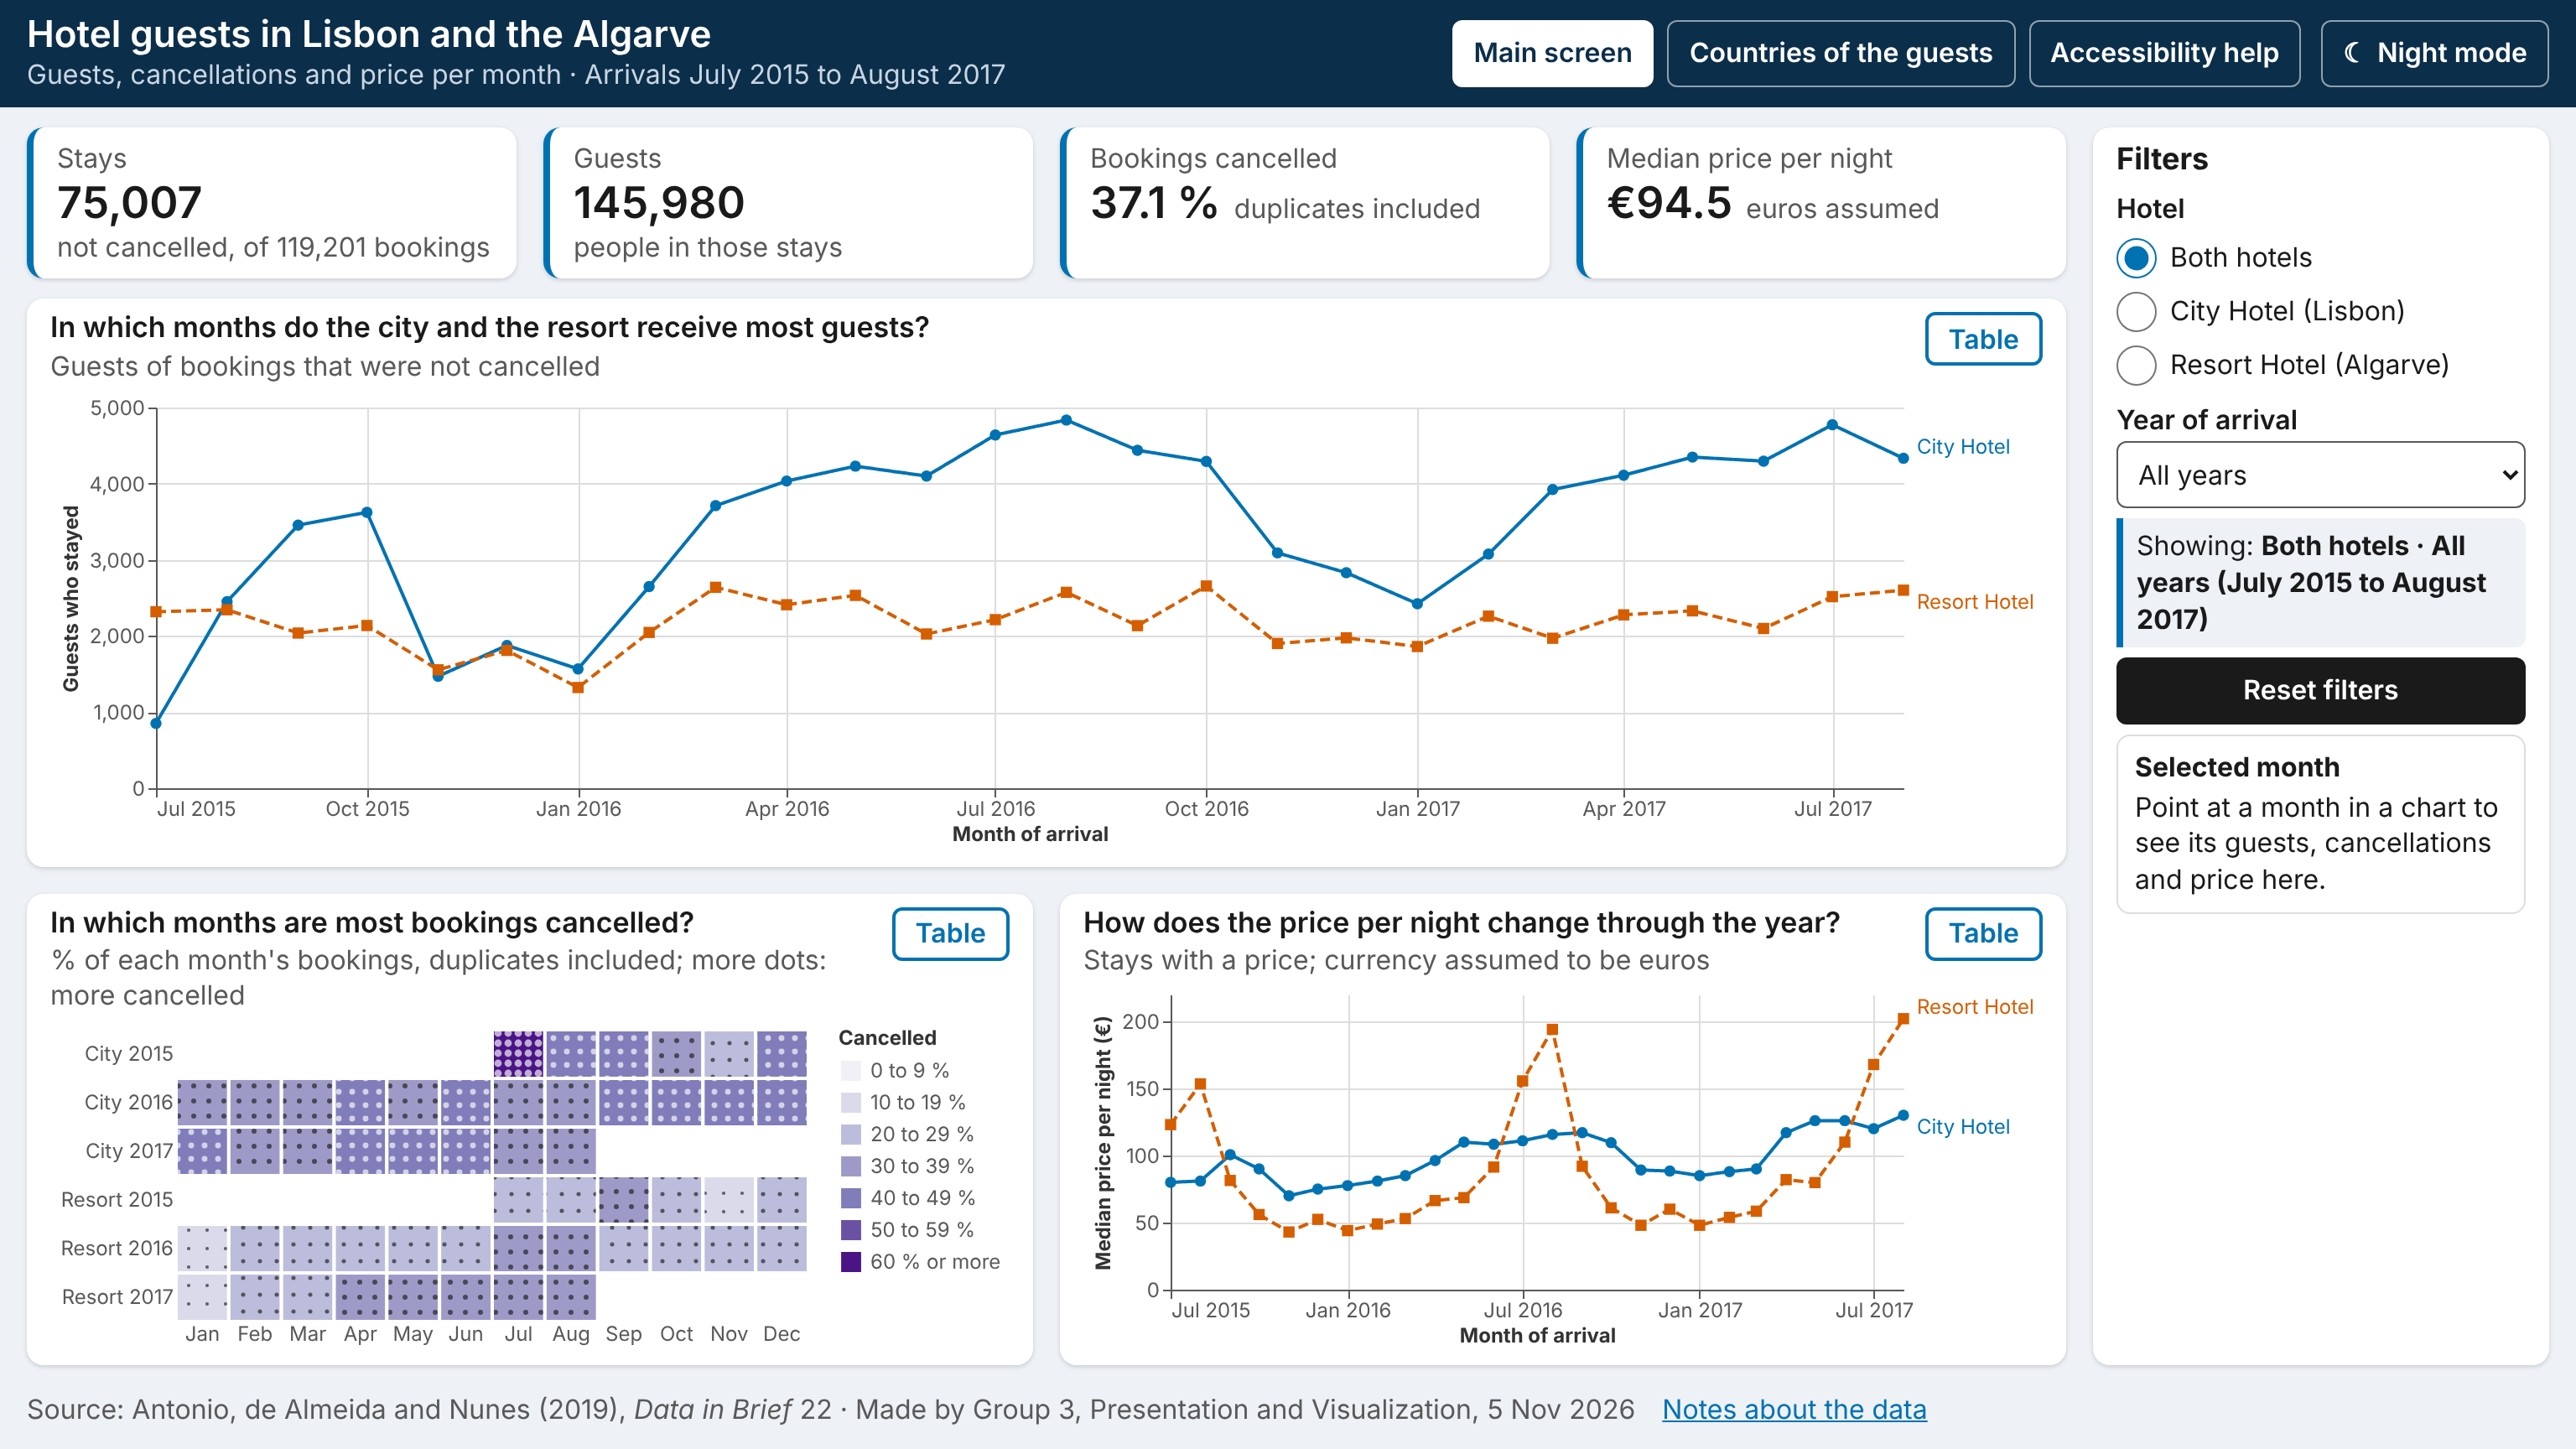

Main screen used with the keyboard


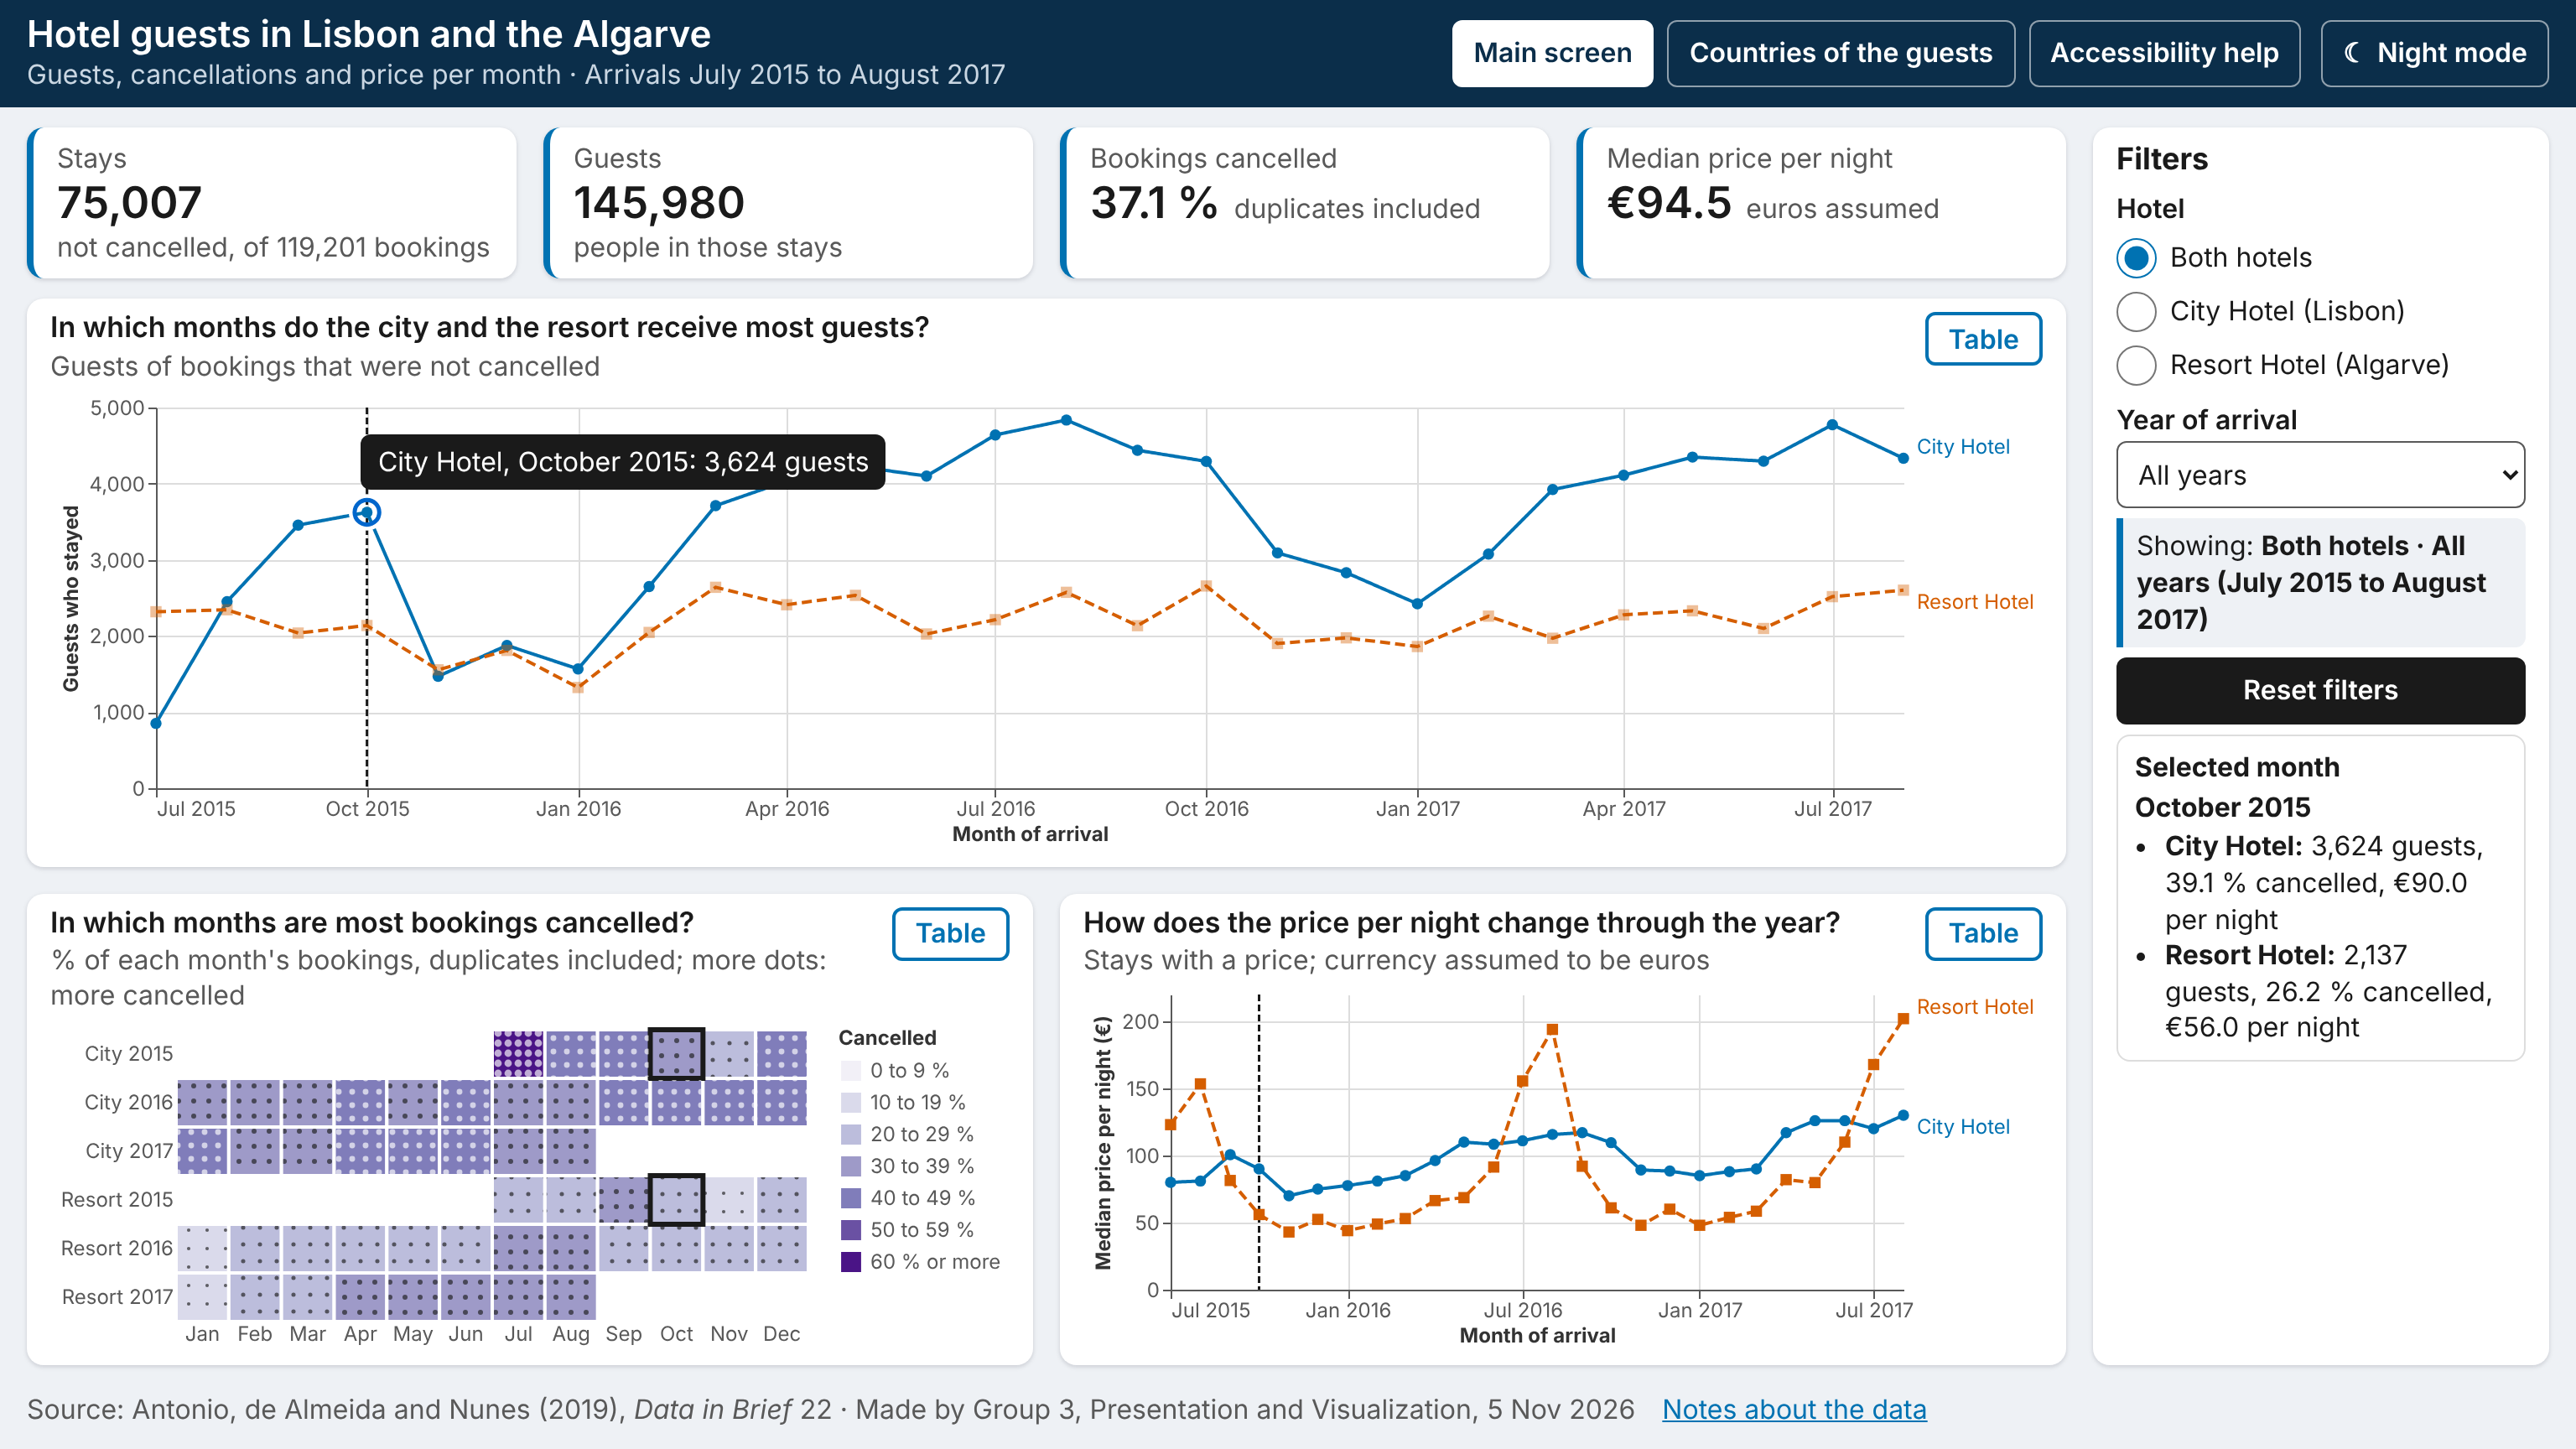

Detail screen at first load (no country selected)


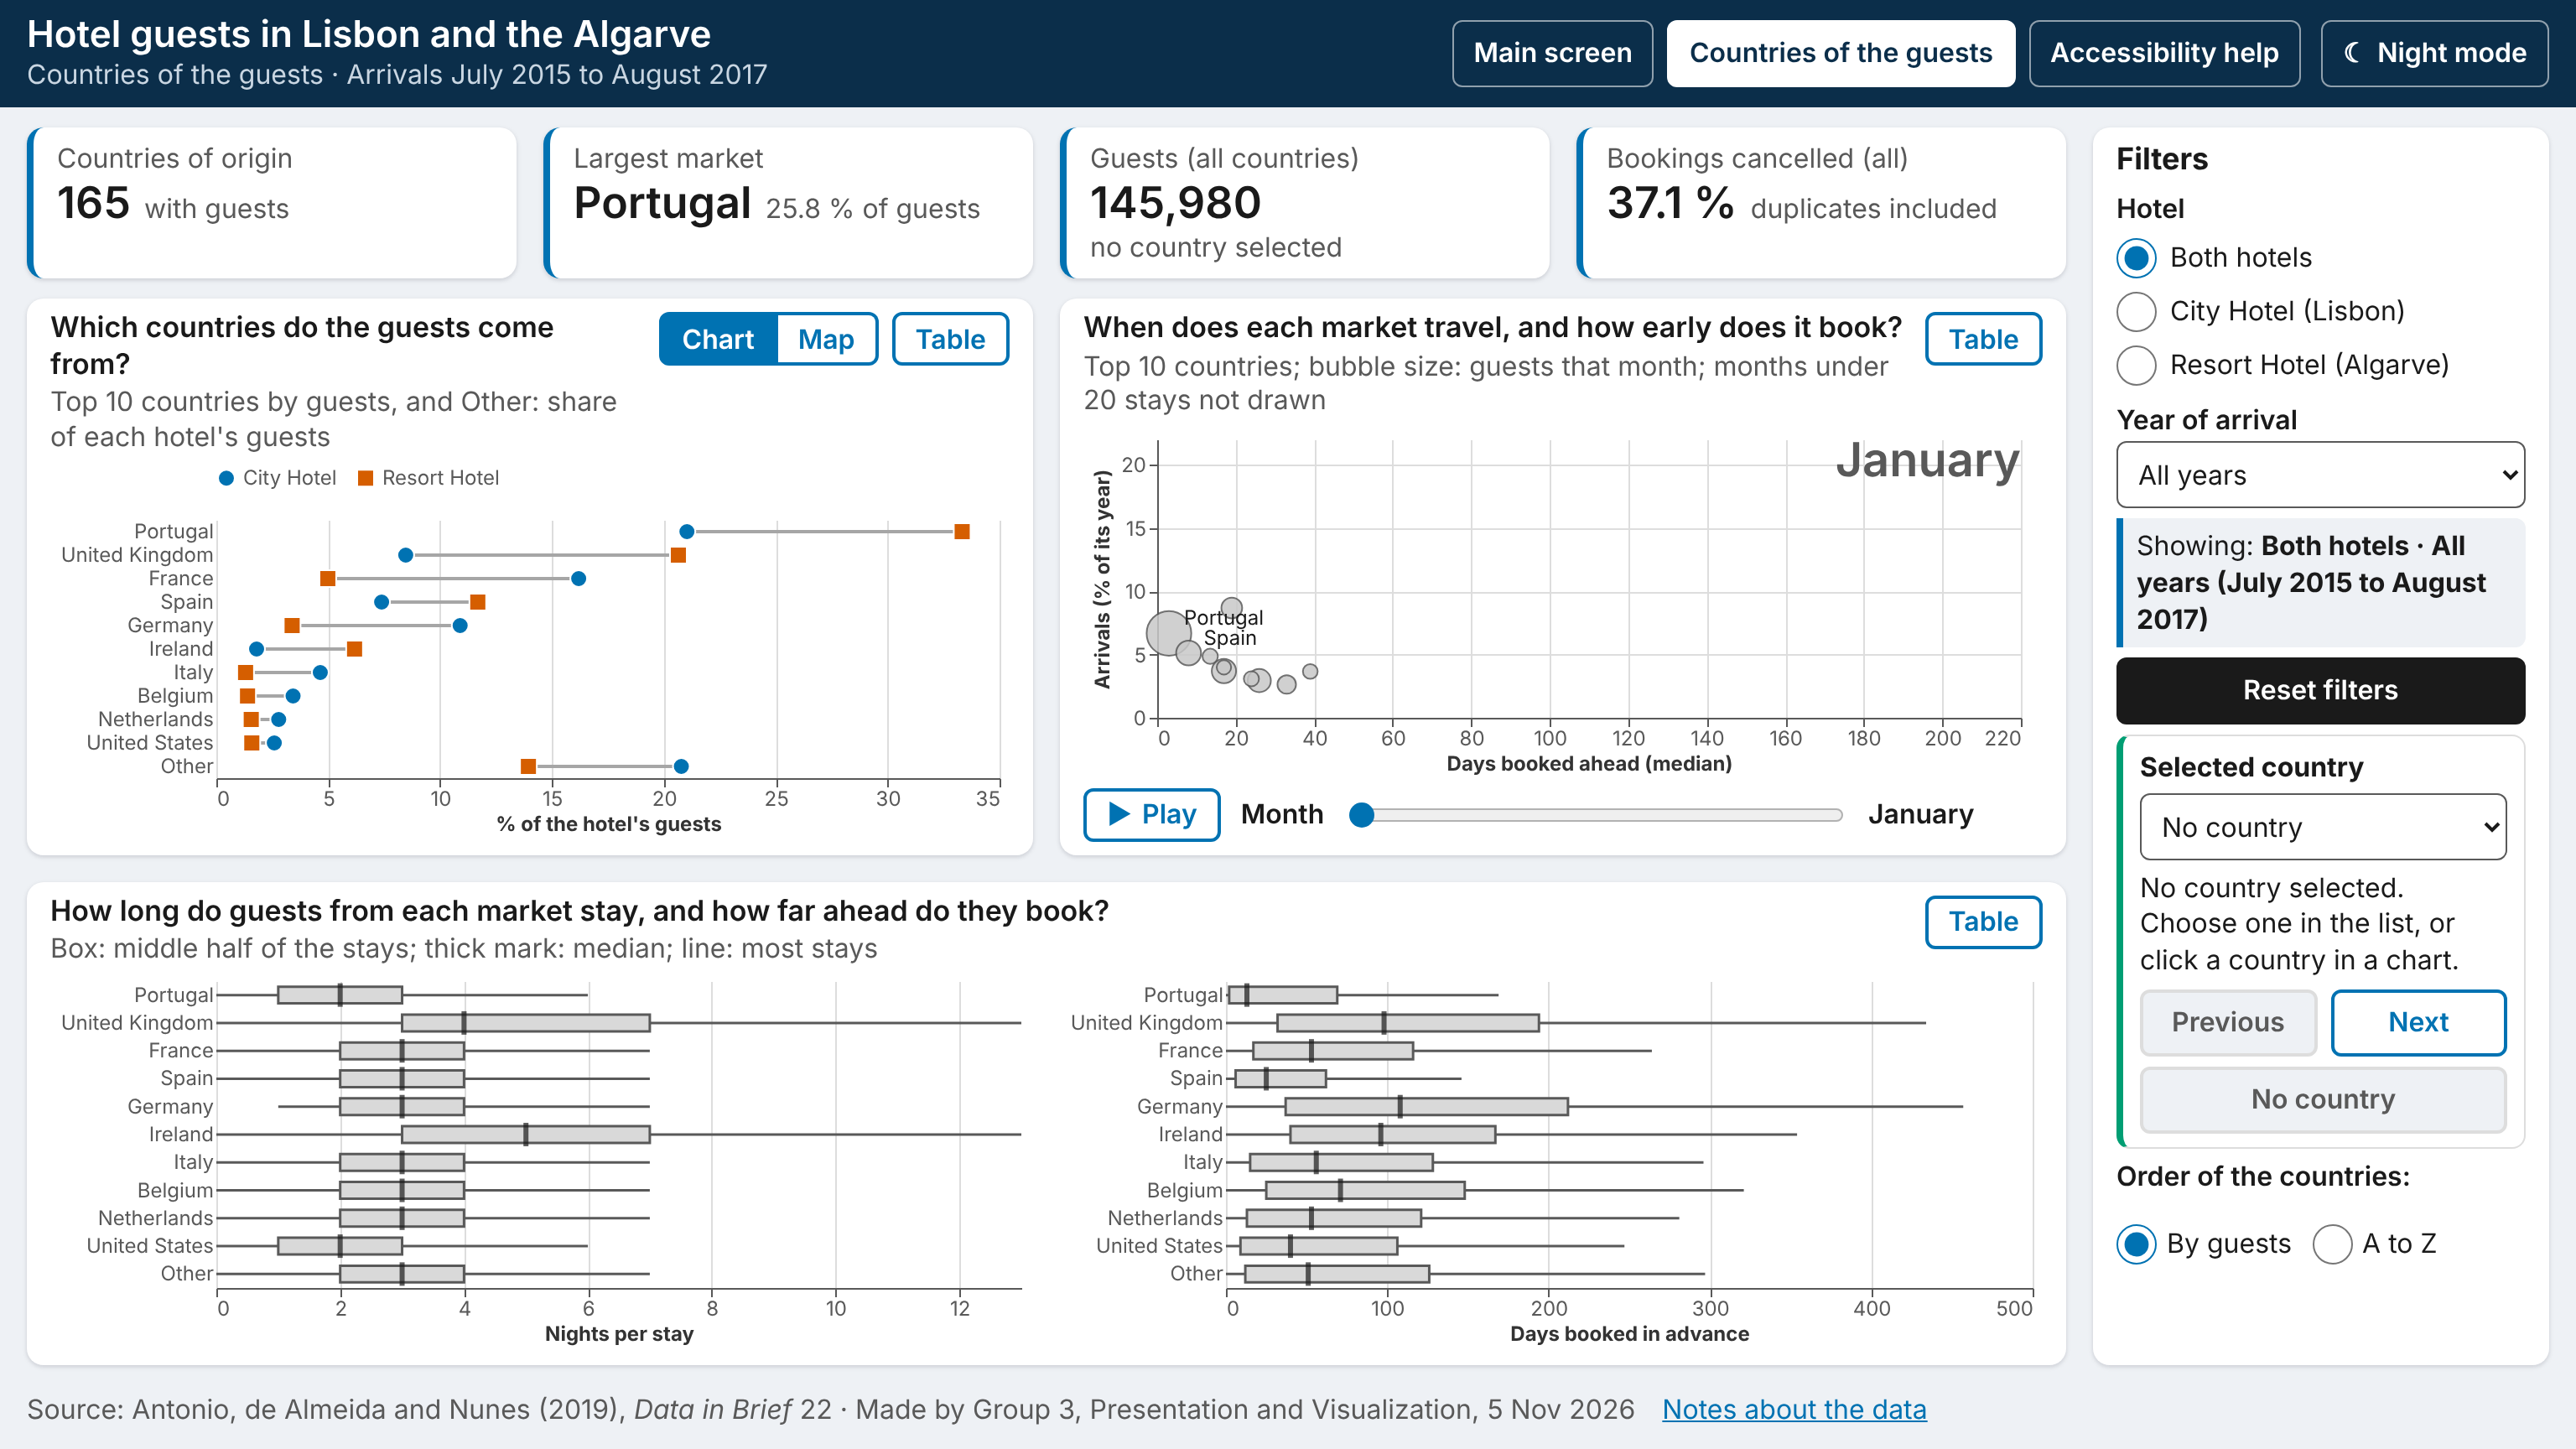

Detail screen in night mode, United Kingdom selected, July


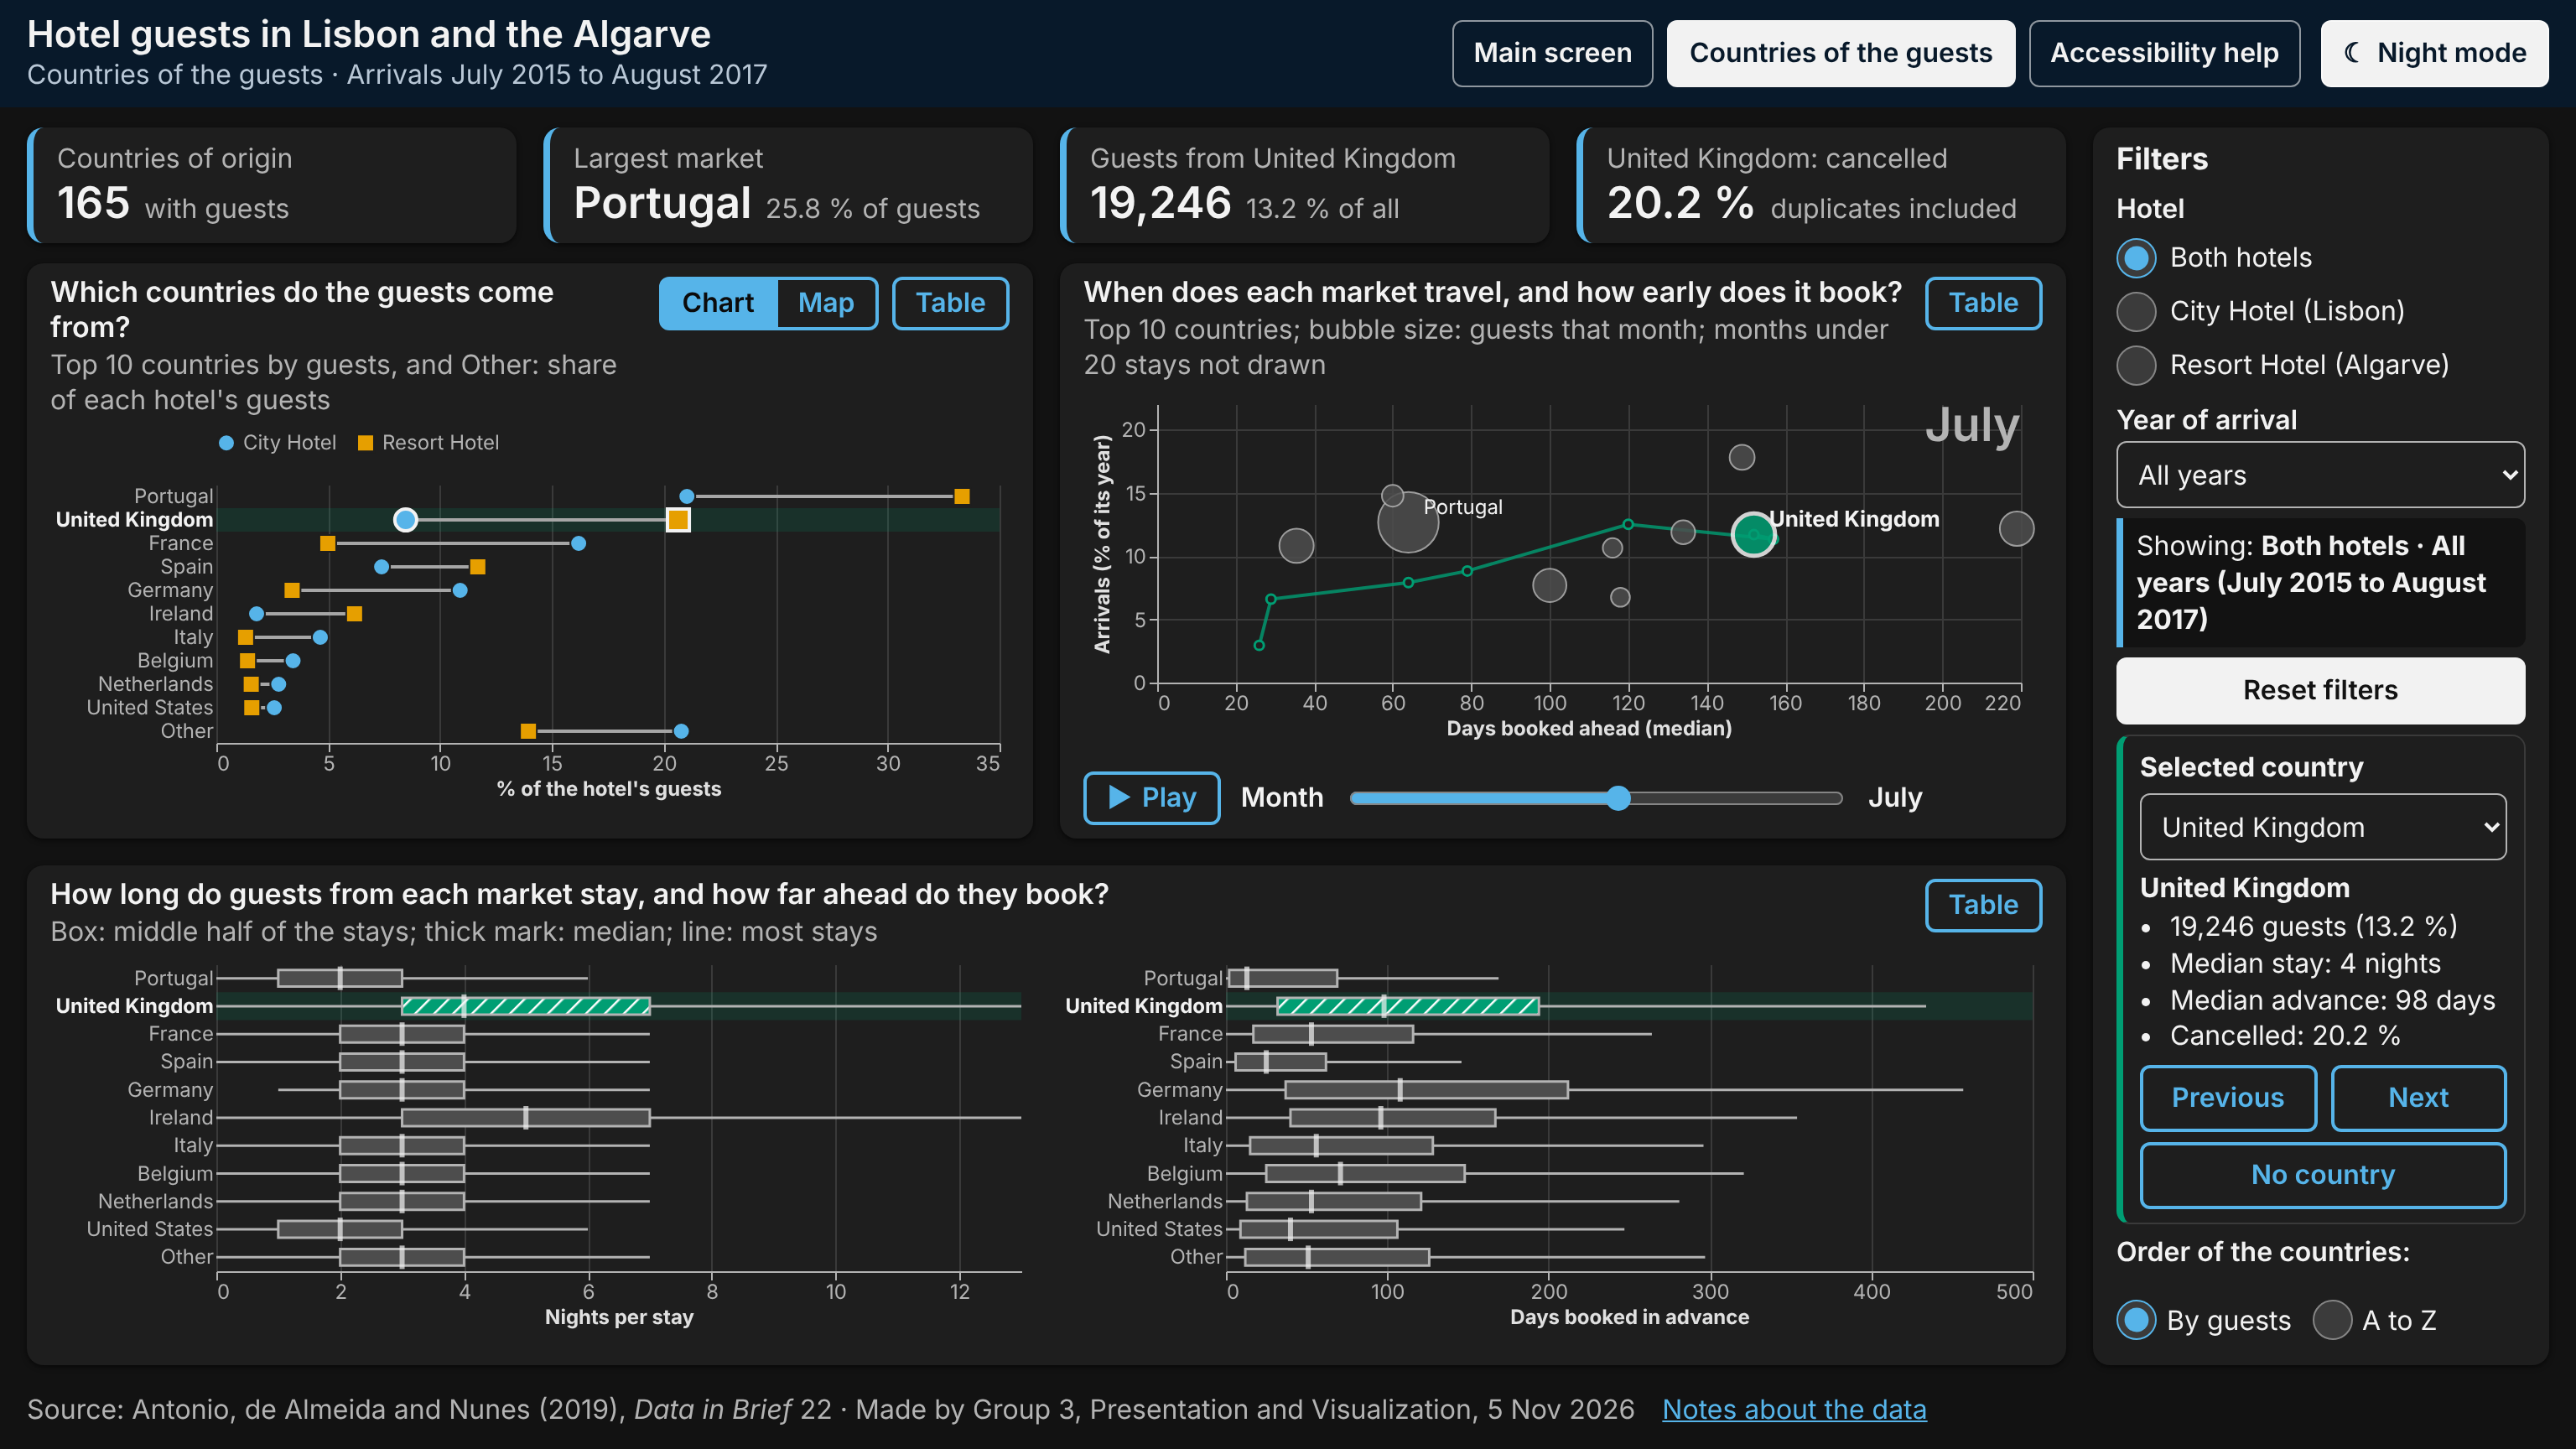

In [11]:
# ── Screenshots for the Part 6 document ──────────────────────────────────────
SCREEN = {'width': 1536, 'height': 864}
for old_image in ['detail_screen_show_more.png']:          # screenshot of the first build ("Show more" no longer exists)
    (IMAGES_DIR / old_image).unlink(missing_ok=True)
shots = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context = await browser.new_context(viewport=SCREEN, device_scale_factor=2, color_scheme='light')
    page = await context.new_page()

    await page.goto((DASHBOARD_DIR / 'index.html').as_uri())
    await page.wait_for_selector('body[data-dashboard-ready="true"]')
    await page.screenshot(path=IMAGES_DIR / 'main_screen.png')
    shots.append(('main_screen.png', 'Main screen at first load'))

    # Keyboard: Tab into C1 (after the links, the night-mode button and its Table button), three right arrows (October 2015)
    for _ in range(8):
        await page.keyboard.press('Tab')
    for _ in range(3):
        await page.keyboard.press('ArrowRight')
    await page.wait_for_timeout(500)
    await page.screenshot(path=IMAGES_DIR / 'main_screen_keyboard.png')
    shots.append(('main_screen_keyboard.png', 'Main screen used with the keyboard'))

    await page.goto((DASHBOARD_DIR / 'detail.html').as_uri())
    await page.wait_for_selector('body[data-dashboard-ready="true"]')
    await page.screenshot(path=IMAGES_DIR / 'detail_screen.png')
    shots.append(('detail_screen.png', 'Detail screen at first load (no country selected)'))

    # Night mode, United Kingdom selected, the animation set to July with the slider
    await page.click('#theme-toggle')
    await page.select_option('#country-select', 'United Kingdom')
    await page.wait_for_timeout(800)
    await page.fill('#frame-month', '7')
    await page.dispatch_event('#frame-month', 'input')
    await page.wait_for_timeout(1500)
    await page.mouse.move(5, 5)
    await page.screenshot(path=IMAGES_DIR / 'detail_screen_night.png')
    shots.append(('detail_screen_night.png', 'Detail screen in night mode, United Kingdom selected, July'))
    await page.click('#theme-toggle')                      # leave the light theme stored for the next visit
    await context.close()
    await browser.close()

from IPython.display import Image, display
for file_name, what in shots:
    print(what)
    display(Image(filename=IMAGES_DIR / file_name, width=640))

## 6. Export

In [12]:
# ── Export the review tables ──────────────────────────────────────────────────
hard.to_csv(OUTPUT_DIR / 'draco_hard_rules_by_chart.csv', index=False)
soft.to_csv(OUTPUT_DIR / 'draco_checklist.csv', index=False)
dataviz.to_csv(OUTPUT_DIR / 'dataviz_checklist.csv', index=False)
notebook_review.to_csv(OUTPUT_DIR / 'notebook_checklist.csv')
other_items.to_csv(OUTPUT_DIR / 'notebook_checklist_other_items.csv', index=False)
wcag.to_csv(OUTPUT_DIR / 'wcag_checklist.csv', index=False)
open_items.to_csv(OUTPUT_DIR / 'open_items.csv', index=False)
pd.DataFrame(shots, columns=['image', 'what']).to_csv(OUTPUT_DIR / 'screenshots.csv', index=False)
sorted(path.name for path in OUTPUT_DIR.iterdir()) + sorted(path.name for path in IMAGES_DIR.glob('*.png'))

['dataviz_checklist.csv',
 'draco_checklist.csv',
 'draco_hard_rules_by_chart.csv',
 'notebook_checklist.csv',
 'notebook_checklist_other_items.csv',
 'open_items.csv',
 'screenshots.csv',
 'wcag_checklist.csv',
 'detail_screen.png',
 'detail_screen_night.png',
 'main_screen.png',
 'main_screen_keyboard.png']

## Conclusions

### Task 6.8 (screenshots and review)
1. Four screenshots of the two screens (light theme, keyboard use and night mode) are in `../images/` for the Part 6 document.
2. DRACO: every hard rule passes on every chart (checked by code on the real specs); the map is outside DRACO and follows the GeoHandout.
3. Data-viz and notebook checklists: met, with two adaptations decided in architecture.md (computer or tablet only; `data.js` instead of `data.json`); on the detail screen no chart takes 40 % of the area, and windows smaller than 1536 × 864 px scroll a little.
4. WCAG 2.2 AA + COGA: met, with the adaptations and the open items listed in section 4.5 for the students.
5. The students approved the first review and asked for two changes (every page text at least 16 px, the header links on one line). They then refined the dashboard in a separate copy (9 November) and approved it before it replaced the first version; this review was run again on the refined dashboard.

### Limitations
- The screenshots and checks come from headless Chromium; the students should look at both screens in their own browser.

### Next steps
- Task 6.9: the Part 6 document (`.md` and `.pdf`).